## Code computing the quantum Wigner function for a Fock state with $\overline{n}=1$

### Imports

In [2]:
%matplotlib inline

from src.wigner_function import wigner_Fock
from src.plot_function import plot_wigner_electron, plot_wigner_photon
from src.wigner_methods import wigner_spectral_convolve, wigner_propagate
from qutip import basis, wigner
import numpy as np

loop over Fock states[████████████████████████████████████████] 50/50 Est wait 00:00.00



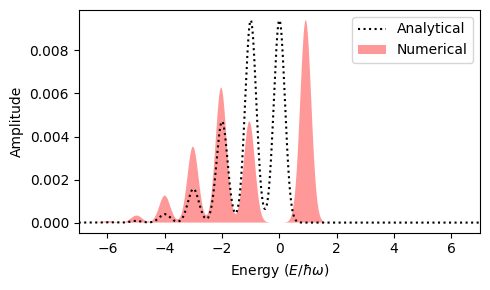

In [ ]:
# Amplitude of the nth peak
from math import factorial
import matplotlib.pyplot as plt
%matplotlib inline

from src.wigner_function import wigner_Fock
from src.plot_function import plot_wigner_electron, plot_wigner_photon
from src.wigner_methods import wigner_spectral_convolve, wigner_propagate
from qutip import basis, wigner
import numpy as np
from src.generic import gaussian


ene_photon=1.55 # Photon energy in eV
# g0=0.4 # Electron-photon coupling constant
nbar=0 # Average number of photons in the cavity
prop_mm=1.0 # propagation distance after interaction in mm
ZLP_width=0.7 # Energy standard deviation in eV

N_space=20 # Dimension of the Hilbert space - needs to be >nbar
psi=basis(N_space,nbar) # Define wavevector
rho=psi * psi.dag() # Calculate Density matrix
xvec = np.linspace(-5,5,200) # Sample the phase-space
W_photon = wigner(rho, xvec, xvec) # Calculate the Wigner function

g0 = 1.0

def Cn0_function(g0, n):
    return np.exp(-np.abs(g0)**2 / 2) * (g0**n) / np.sqrt(factorial(n))

def generate_spectrum(p_axis, g0, n_max, sig):
    spectrum = np.zeros_like(p_axis, dtype=float)

    for n in range(n_max + 1):
        amplitude = np.abs(Cn0_function(g0, n))**2
        spectrum += amplitude * gaussian(p_axis, -n, sig)

    return spectrum

Wigner_Fock, sidebands_axis, z_axis  = wigner_Fock(ene_photon,g0,nbar,method="numerical")
# Convolve with ZLP
Wigner_convolved, p_axis = wigner_spectral_convolve(Wigner_Fock, ene_photon, ZLP_width)
# Propagation after interaction
W_electron= Wigner_convolved #wigner_propagate(Wigner_convolved, p_axis, ene_photon, prop_mm)

ene_photon = 1.55 # Photon energy in eV
n_max = 10
sig = 0.192 # Width in units of photon energy

spectrum_analytical = generate_spectrum(p_axis, g0, n_max, sig)
energy_spectrum_wigner=W_electron.sum(axis=1)

plt.figure(figsize=(5, 3))

plt.plot(
    p_axis,
    spectrum_analytical / np.sum(spectrum_analytical),
    color='black',
    linestyle=':',
    linewidth=1.5,
    label='Analytical'
)

plt.fill_between(
    p_axis + 0.17,
    0,
    energy_spectrum_wigner / np.sum(energy_spectrum_wigner),
    color='red',
    alpha=0.4,
    linewidth=0,
    label='Numerical'
)

plt.xlim((-7,7))

plt.xlabel(r'Energy ($E/\hbar\omega$)')
plt.ylabel('Amplitude')
plt.legend()
plt.tight_layout()
plt.show()

### Simulations input

In [3]:
ene_photon=1.55 # Photon energy in eV
g0=0.4 # Electron-photon coupling constant
nbar=1 # Average number of photons in the cavity
prop_mm=1.0 # propagation distance after interaction in mm
ZLP_width=0.7 # Energy standard deviation in eV

In [8]:
import numpy as np
from math import sqrt, pi
from scipy.special import jv

from src.state_amplitude import alpha_Fock_analytical, alpha_coherent_analytical, alpha_Fock_Qutip, alpha_coherent_Qutip,Fnl
from src.generic import progressbar
from src.units_contants import eV, v
from src.simulation_parameters import number_of_periods, nmax, Nz, maxit, N_space

# wigner_Fock(ene_photon,g0,nbar,method,option=None)
method = "numerical"
nFock = 0
option = None
ind_table=np.linspace(0,maxit+nmax+1,maxit+nmax+2)
alpha_table=ind_table*0.0*1j
if method=="analytical":
    for i in range(np.size(ind_table)):
        alpha_table[i]=alpha_Fock_analytical(i,nbar)
elif method=="numerical":
    alpha_table=alpha_Fock_Qutip(ind_table,nbar,N_space)
else:
    print('Invalid method - switch to analytical by default')
    for i in range(np.size(ind_table)):
        alpha_table[i]=alpha_Fock_analytical(i,nbar)
# wignerQ(ene_photon,g0,alpha_table,maxit,option)

qz = ene_photon*eV/v 

# Table of indices of the sidebands
sidebands_axis=np.linspace(-nmax, nmax, 2*nmax+1, dtype=int)

# Sampling of the z-axis for the number of periods we have chosen
z = number_of_periods*pi*np.linspace(-1,1,Nz)/qz

# Initialize the wigner functions
wigner_exact=np.zeros((2*nmax+1,Nz))*1j # Exact Wigner function

# Compute the amplitude of each sidebands for a Fock state of average number nbar
amplitude=np.zeros(2*nmax+1)*1j
for n_l in range(2*nmax+1):
    lsideband=sidebands_axis[n_l]
    if max(-lsideband,0)>nFock:
        amplitude[n_l]=0
    else:    
        amplitude[n_l]=alpha_table[nFock+lsideband]*Fnl(nFock,lsideband,g0,option)

# Compute the exact Wigner function
for j in range(Nz):
    Psi = amplitude*np.exp(1j*sidebands_axis*qz*z[j])
    wigner_exact[:,j] = np.convolve(Psi,np.conj(Psi),'same')

pw = wigner_exact, sidebands_axis, z

wigner_init, sidebands_axis,z=pw
wigner_full_array=np.zeros((np.size(wigner_init[:,0]),np.size(wigner_init[0,:]),maxit))*1j

for k in progressbar(range(maxit),"loop over Fock states",40):
    wigner_loop, sidebands_axis,z=pw
    wigner_full_array[:,:,k]=wigner_loop

result = np.real(np.sum(wigner_full_array,axis=2)), sidebands_axis, z

loop over Fock states[████████████████████████████████████████] 50/50 Est wait 00:00.00



In [10]:
Psi

array([ 0.        +0.00000000e+00j, -0.        +0.00000000e+00j,
        0.        +0.00000000e+00j,  0.        -0.00000000e+00j,
        0.        +0.00000000e+00j,  0.        -0.00000000e+00j,
        0.        +0.00000000e+00j,  0.        -0.00000000e+00j,
        0.        +0.00000000e+00j,  0.        -0.00000000e+00j,
        0.        +0.00000000e+00j,  0.        -0.00000000e+00j,
        0.        +0.00000000e+00j,  0.        -0.00000000e+00j,
        0.        +0.00000000e+00j, -0.        +0.00000000e+00j,
        0.        +0.00000000e+00j,  0.        -0.00000000e+00j,
        0.        +0.00000000e+00j,  0.        -0.00000000e+00j,
        0.        +0.00000000e+00j,  0.        -0.00000000e+00j,
        0.        +0.00000000e+00j,  0.        -0.00000000e+00j,
        0.        +0.00000000e+00j,  0.        -0.00000000e+00j,
        0.        +0.00000000e+00j,  0.        -0.00000000e+00j,
        0.        +0.00000000e+00j,  0.        -0.00000000e+00j,
        0.        +0.0000

### Compute the initial photon Wigner function

In [4]:
N_space=20 # Dimension of the Hilbert space - needs to be >nbar
psi=basis(N_space,nbar) # Define wavevector
rho=psi * psi.dag() # Calculate Density matrix
xvec = np.linspace(-5,5,200) # Sample the phase-space
W_photon = wigner(rho, xvec, xvec) # Calculate the Wigner function

### Plot the initial photon Wigner function

c:\Users\adteurtrie\travail\vscodes\pyIELS\notebooks\src\plot_function.py:159: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


GridSpec(2, 2, height_ratios=[1.0, 2.0], width_ratios=[2.0, 1.0])

findfont: Font family ['STIXGeneral'] not found. Falling back to DejaVu Sans.
findfont: Font family ['STIXGeneral'] not found. Falling back to DejaVu Sans.
findfont: Font family ['STIXGeneral'] not found. Falling back to DejaVu Sans.
findfont: Font family ['STIXGeneral'] not found. Falling back to DejaVu Sans.
findfont: Font family ['STIXNonUnicode'] not found. Falling back to DejaVu Sans.
findfont: Font family ['STIXNonUnicode'] not found. Falling back to DejaVu Sans.
findfont: Font family ['STIXNonUnicode'] not found. Falling back to DejaVu Sans.
findfont: Font family ['STIXSizeOneSym'] not found. Falling back to DejaVu Sans.
findfont: Font family ['STIXSizeTwoSym'] not found. Falling back to DejaVu Sans.
findfont: Font family ['STIXSizeThreeSym'] not found. Falling back to DejaVu Sans.
findfont: Font family ['STIXSizeFourSym'] not found. Falling back to DejaVu Sans.
findfont: Font family ['STIXSizeFiveSym'] not found. Falling back to DejaVu Sans.
findfont: Font family ['cmsy10'] not

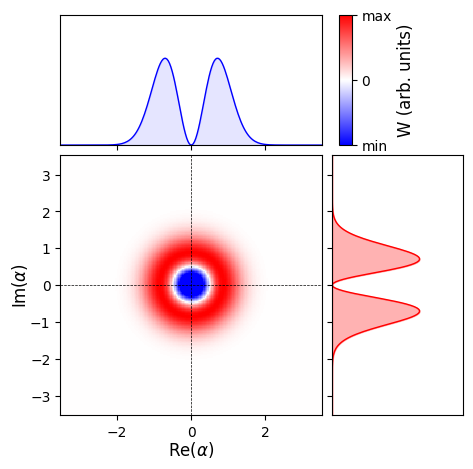

In [5]:
plot_wigner_photon(W_photon, xvec, xvec)

### Compute the electron Wigner function

In [6]:
# Compute the exact electron Wigner function
Wigner_Fock, sidebands_axis, z_axis  = wigner_Fock(ene_photon,g0,nbar,method="numerical")
# Convolve with ZLP
Wigner_convolved, p_axis = wigner_spectral_convolve(Wigner_Fock, ene_photon, ZLP_width)
# Propagation after interaction
W_electron=wigner_propagate(Wigner_convolved, p_axis, ene_photon, prop_mm)

loop over Fock states[████████████████████████████████████████] 50/50 Est wait 00:00.00



### Plot the Wigner function together with the marginal distributions

c:\Users\adteurtrie\travail\vscodes\pyIELS\notebooks\src\plot_function.py:86: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


GridSpec(2, 2, height_ratios=[1, 2], width_ratios=[3, 1])

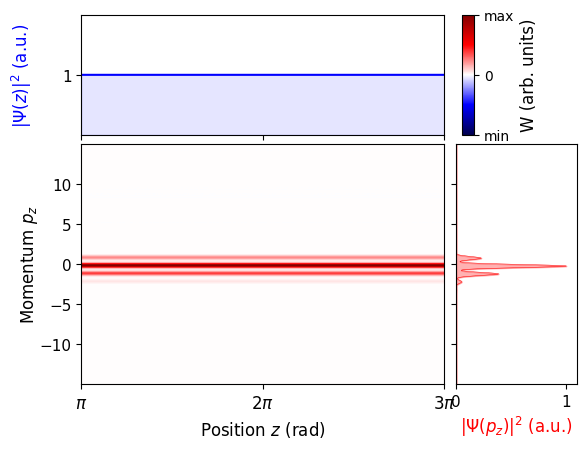

In [7]:
plot_wigner_electron(W_electron, p_axis, z_axis, ene_photon)

In [ ]:
qz = ene_photon*eV/v          
dispersion = 40
# ZLP FWHM and standard deviation in sideband space
ZLP_fwhm=eV*ZLP_width/(qz*v) 
ZLP_sig=ZLP_fwhm/(2*np.sqrt(2*np.log(2)))        

# Calculate the number of sampling point in the sidebands space
Np=int((2*nmax+1)*dispersion)
# Sampling the sidebands space
p_axis=np.linspace(-nmax, nmax, Np)/2

# Define the ZLP
from utils import gaussian
ZLP=gaussian(p_axis, 0.0, ZLP_sig) # Calculate the ZLP

# Initialize the new Wigner function
wigner_convolved=np.zeros((Np,Nz))*1j # Wigner function including the spectral width of the electron source
# Convolve with ZLP
wigner_convolved[0::dispersion,:]=wigner
wigner_convolved=signal.fftconvolve(wigner_convolved,np.expand_dims(ZLP,axis=1),'same')

TypeError: must be real number, not function

In [2]:
import numpy as np

np.complex

AttributeError: module 'numpy' has no attribute 'complex'.
`np.complex` was a deprecated alias for the builtin `complex`. To avoid this error in existing code, use `complex` by itself. Doing this will not modify any behavior and is safe. If you specifically wanted the numpy scalar type, use `np.complex128` here.
The aliases was originally deprecated in NumPy 1.20; for more details and guidance see the original release note at:
    https://numpy.org/devdocs/release/1.20.0-notes.html#deprecations